In [1]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
import random

# Sample text corpus
corpus = [
    "the sun is shining",
    "the weather is sweet",
    "make you want to move",
    "your dancing feet",
    "to the rescue here I am",
    "want you to know",
    "where I stand",
    "I love hot dogs",
    "Alice is beatiful",
    "John is standing there",
    "this is a nice morning",
    "the dog is called sparkie",
    "there is a ball in the beach"
]

# Step 1: Tokenize the text
tokenizer = Tokenizer()
tokenizer.fit_on_texts(corpus)
total_words = len(tokenizer.word_index) + 1

# Convert text into sequences of tokens
input_sequences = []
for line in corpus:
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

# Pad sequences and split into inputs (X) and outputs (y)
max_seq_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_seq_len, padding='pre')

X, y = input_sequences[:, :-1], input_sequences[:, -1]
y = np.array(y)

# Step 2: Build the LSTM model
model = Sequential([
    Embedding(total_words, 10, input_length=max_seq_len - 1),
    LSTM(50),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Convert output labels (y) to categorical format
from tensorflow.keras.utils import to_categorical
y = to_categorical(y, num_classes=total_words)

# Train the model
model.fit(X, y, epochs=100, verbose=2)


Epoch 1/100


D:\deep-learning-labs\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:117: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


2/2 - 1s - 713ms/step - accuracy: 0.0227 - loss: 3.6892
Epoch 2/100
2/2 - 1s - 667ms/step - accuracy: 0.1818 - loss: 3.6854
Epoch 3/100
2/2 - 0s - 36ms/step - accuracy: 0.1591 - loss: 3.6820
Epoch 4/100
2/2 - 0s - 37ms/step - accuracy: 0.1591 - loss: 3.6785
Epoch 5/100
2/2 - 0s - 40ms/step - accuracy: 0.1591 - loss: 3.6747
Epoch 6/100
2/2 - 0s - 20ms/step - accuracy: 0.1591 - loss: 3.6704
Epoch 7/100
2/2 - 0s - 17ms/step - accuracy: 0.1591 - loss: 3.6656
Epoch 8/100
2/2 - 0s - 17ms/step - accuracy: 0.1591 - loss: 3.6599
Epoch 9/100
2/2 - 0s - 18ms/step - accuracy: 0.1591 - loss: 3.6534
Epoch 10/100
2/2 - 0s - 17ms/step - accuracy: 0.1591 - loss: 3.6456
Epoch 11/100
2/2 - 0s - 17ms/step - accuracy: 0.1591 - loss: 3.6363
Epoch 12/100
2/2 - 0s - 16ms/step - accuracy: 0.1591 - loss: 3.6249
Epoch 13/100
2/2 - 0s - 17ms/step - accuracy: 0.1591 - loss: 3.6111
Epoch 14/100
2/2 - 0s - 17ms/step - accuracy: 0.1591 - loss: 3.5941
Epoch 15/100
2/2 - 0s - 17ms/step - accuracy: 0.1591 - loss: 3.5730

In [2]:
# Step 3: Predict the next word
def predict_next_word(model, tokenizer, input_text, max_seq_len):
    token_list = tokenizer.texts_to_sequences([input_text])[0]
    token_list = pad_sequences([token_list], maxlen=max_seq_len - 1, padding='pre')
    predicted_probs = model.predict(token_list, verbose=0)
    predicted_word_index = np.argmax(predicted_probs)
    for word, index in tokenizer.word_index.items():
        if index == predicted_word_index:
            return word
    return None

# Step 4: Test the model
seed_text = "the sun"
next_word = predict_next_word(model, tokenizer, seed_text, max_seq_len)
#print(f"Seed Text: '{seed_text}' -> Next Word: '{next_word}'")

# Generate a sequence of text
def generate_text(model, tokenizer, seed_text, next_words, max_seq_len):
    for _ in range(next_words):
        next_word = predict_next_word(model, tokenizer, seed_text, max_seq_len)
        if next_word:
            seed_text += " " + next_word
    return seed_text

generated_text = generate_text(model, tokenizer, "John is standing", 4, max_seq_len)
print(f"Generated Text: '{generated_text}'")


Generated Text: 'John is standing there there there there'


- Train during 500 epochs and graph the results and observe how metric improves.
- Try different senteces lenghts (1, 3, 5) and report
- Try different sizes of lstm modules #   LSTM(50), 10, 20

In [3]:
import sys
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
from tensorflow.keras.utils import set_random_seed

# Permite importar src al iniciar Jupyter desde la carpeta del notebook.
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Ejecuta el notebook dentro del proyecto deep-learning-labs.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import PROJECT_PATH
from src.utils import logger as log

logger = log.LOGGER
config = log.CONFIG
figure_directory = Path(config.paths.reports.figures)
if not figure_directory.exists():
    logger.warning("La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.")
    figure_directory = PROJECT_PATH / figure_directory
figure_directory.mkdir(parents=True, exist_ok=True)

def comparar_lstm(longitudes=(1, 3, 5), unidades=(50, 10, 20), epochs=500, verbose=0):
    """Compara contextos y unidades LSTM usando el corpus y tokenizer anteriores.

    Cada longitud es el número máximo de palabras previas; los contextos más
    cortos se rellenan y los más largos se truncan por la izquierda. Se usan
    los mismos ejemplos para todas las configuraciones. Las métricas son de
    entrenamiento, no miden generalización. Devuelve modelos e historiales.
    """
    longitudes, unidades = tuple(longitudes), tuple(unidades)
    for nombre, valores in (("longitudes", longitudes), ("unidades", unidades), ("epochs", (epochs,))):
        if not valores or any(not isinstance(valor, int) or isinstance(valor, bool) or valor < 1 for valor in valores):
            raise ValueError(f"{nombre} debe contener enteros positivos")
    if len(set(longitudes)) != len(longitudes) or len(set(unidades)) != len(unidades):
        raise ValueError("Las longitudes y unidades no deben repetirse")

    contextos, objetivos = [], []
    for linea in corpus:
        tokens = tokenizer.texts_to_sequences([linea])[0]
        for i in range(1, len(tokens)):
            contextos.append(tokens[:i])
            objetivos.append(tokens[i])
    if not contextos:
        raise ValueError("El corpus debe contener al menos una secuencia de dos palabras")
    etiquetas = to_categorical(np.array(objetivos), num_classes=total_words)

    resultados = []
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for longitud in longitudes:
        entradas = pad_sequences(contextos, maxlen=longitud, padding='pre', truncating='pre')
        for n_unidades in unidades:
            set_random_seed(config.project.get('seed', 42))
            modelo = Sequential([
                Embedding(total_words, 10),
                LSTM(n_unidades),
                Dense(total_words, activation='softmax')
            ])
            modelo.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
            historial = modelo.fit(entradas, etiquetas, epochs=epochs, verbose=verbose).history
            etiqueta = f"Contexto={longitud}, LSTM={n_unidades}"
            axes[0].plot(range(1, len(historial['accuracy']) + 1), historial['accuracy'], label=etiqueta)
            axes[1].plot(range(1, len(historial['loss']) + 1), historial['loss'], label=etiqueta)
            print(f"{etiqueta}: accuracy {historial['accuracy'][0]:.4f} -> "
                  f"{historial['accuracy'][-1]:.4f}, loss {historial['loss'][0]:.4f} -> "
                  f"{historial['loss'][-1]:.4f}")
            resultados.append({'longitud': longitud, 'unidades': n_unidades,
                               'modelo': modelo, 'historial': historial})

    for axis, titulo in zip(axes, ('Accuracy de entrenamiento', 'Loss de entrenamiento')):
        axis.set_title(titulo)
        axis.set_xlabel('Época')
        axis.set_ylabel(titulo)
        axis.legend()
        axis.grid(True, alpha=0.3)
    fig.tight_layout()
    ruta_figura = figure_directory / f"comparacion_lstm_{uuid4().hex}.png"
    fig.savefig(ruta_figura, dpi=150, bbox_inches='tight')
    logger.info("Gráfica guardada en %s", ruta_figura)
    plt.show()
    return resultados

# Ejecuta las nueve combinaciones durante 500 épocas:
# resultados = comparar_lstm(longitudes=(1, 3, 5), unidades=(50, 10, 20), epochs=500)


2026-11-25 08:16:46 [WARNING] La carpeta de figuras no existe en la ruta actual; se usará la del proyecto.


Contexto=1, LSTM=50: accuracy 0.0227 -> 0.6364, loss 3.6883 -> 0.7706
Contexto=1, LSTM=10: accuracy 0.0000 -> 0.6136, loss 3.6891 -> 1.1358
Contexto=1, LSTM=20: accuracy 0.0227 -> 0.6364, loss 3.6894 -> 0.8630
Contexto=3, LSTM=50: accuracy 0.0000 -> 0.9545, loss 3.6891 -> 0.1322
Contexto=3, LSTM=10: accuracy 0.0000 -> 0.7045, loss 3.6892 -> 1.1949
Contexto=3, LSTM=20: accuracy 0.0227 -> 0.9091, loss 3.6899 -> 0.4383
Contexto=5, LSTM=50: accuracy 0.0455 -> 0.9545, loss 3.6891 -> 0.1539
Contexto=5, LSTM=10: accuracy 0.0227 -> 0.6818, loss 3.6888 -> 1.2764
Contexto=5, LSTM=20: accuracy 0.0455 -> 0.8636, loss 3.6902 -> 0.6096


2026-11-25 08:20:49 [INFO] Gráfica guardada en D:\deep-learning-labs\reports\figures\comparacion_lstm_7649c49d6ff5487cba2922176e615690.png


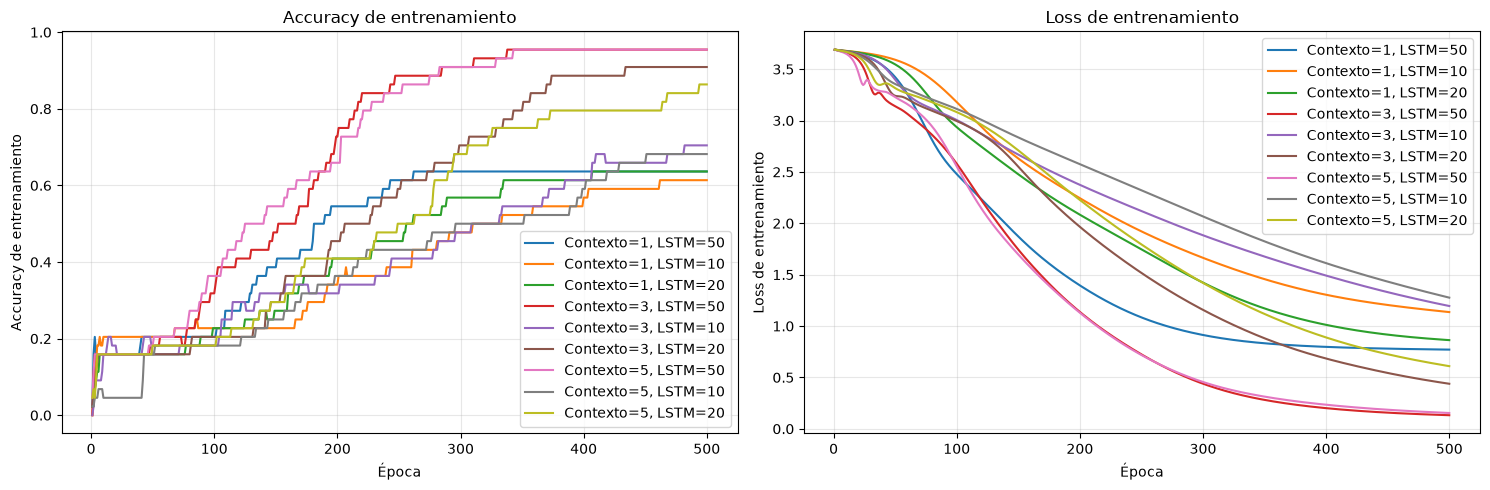

In [4]:
resultados = comparar_lstm(longitudes=(1, 3, 5), unidades=(50, 10, 20), epochs=500)

In [5]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

def explorar_frases(frases=None, palabras_a_generar=4, limite_corta=3):
    """Prueba frases con el modelo existente y compara sus contextos."""
    if frases is None:
        frases = [
            'the sun', 'the weather', 'make you', 'your dancing',
            'I love', 'John is', 'the dog', 'there is',
            'the sun is shining', 'the weather is sweet',
            'make you want to move', 'to the rescue here I am',
            'John is standing there', 'this is a nice morning',
            'the dog is called sparkie', 'there is a ball in the beach',
        ]
    if isinstance(frases, str):
        raise ValueError('frases debe ser una lista de textos, no un solo texto')
    frases = list(frases)
    if not frases or any(not isinstance(frase, str) or not frase.strip() for frase in frases):
        raise ValueError('frases debe contener textos no vacios')
    for nombre, valor in [('palabras_a_generar', palabras_a_generar), ('limite_corta', limite_corta)]:
        if not isinstance(valor, int) or isinstance(valor, bool) or valor < 1:
            raise ValueError(f'{nombre} debe ser un entero positivo')

    capacidad = max_seq_len - 1
    resultados = []
    for frase in frases:
        palabras = text_to_word_sequence(frase, filters=tokenizer.filters,
                                         lower=tokenizer.lower, split=tokenizer.split)
        if not palabras:
            raise ValueError(f'La frase no contiene palabras: {frase!r}')
        desconocidas = [palabra for palabra in palabras if palabra not in tokenizer.word_index]
        tokens = tokenizer.texts_to_sequences([frase])[0]
        if not tokens:
            raise ValueError(f'La frase no contiene palabras del vocabulario: {frase!r}')
        siguiente = predict_next_word(model, tokenizer, frase, max_seq_len)
        generado = generate_text(model, tokenizer, frase, palabras_a_generar, max_seq_len)
        grupo = 'corta' if len(palabras) <= limite_corta else 'larga'
        resultado = {
            'frase': frase, 'grupo': grupo, 'palabras': len(palabras),
            'desconocidas': desconocidas, 'tokens_usados': min(len(tokens), capacidad),
            'tokens_descartados': max(0, len(tokens) - capacidad),
            'siguiente': siguiente, 'generado': generado,
        }
        resultados.append(resultado)
        print(f"[{grupo}] {frase!r} -> siguiente: {siguiente!r} | generado: {generado!r}")
        print(f"  Palabras: {len(palabras)}; tokens usados: {resultado['tokens_usados']}; "
              f"descartados por longitud: {resultado['tokens_descartados']}; "
              f"desconocidas: {desconocidas or 'ninguna'}")

    print(f'\nComparacion (cortas: hasta {limite_corta} palabras; capacidad: {capacidad} tokens):')
    for grupo in ('corta', 'larga'):
        items = [resultado for resultado in resultados if resultado['grupo'] == grupo]
        if items:
            promedio = sum(item['tokens_usados'] for item in items) / len(items)
            truncadas = sum(item['tokens_descartados'] > 0 for item in items)
            print(f'{grupo.capitalize()}s: {len(items)} frases, {promedio:.1f} tokens usados en promedio, '
                  f'{truncadas} con truncamiento.')
        else:
            print(f'{grupo.capitalize()}s: sin frases para comparar.')
    print('Las palabras desconocidas se ignoran con el tokenizer actual. La comparacion es '
          'descriptiva: no mide precision ni calidad sin respuestas esperadas.')
    return resultados

# cortas: hasta 3 palabras; largas: más de 3 palabras; capacidad: max_seq_len - 1 tokens
resultados_frases = explorar_frases()


[corta] 'the sun' -> siguiente: 'is' | generado: 'the sun is a there there'
  Palabras: 2; tokens usados: 2; descartados por longitud: 0; desconocidas: ninguna
[corta] 'the weather' -> siguiente: 'is' | generado: 'the weather is a there there'
  Palabras: 2; tokens usados: 2; descartados por longitud: 0; desconocidas: ninguna
[corta] 'make you' -> siguiente: 'you' | generado: 'make you you to move move'
  Palabras: 2; tokens usados: 2; descartados por longitud: 0; desconocidas: ninguna
[corta] 'your dancing' -> siguiente: 'is' | generado: 'your dancing is a there in'
  Palabras: 2; tokens usados: 2; descartados por longitud: 0; desconocidas: ninguna
[corta] 'I love' -> siguiente: 'a' | generado: 'I love a there in beach'
  Palabras: 2; tokens usados: 2; descartados por longitud: 0; desconocidas: ninguna
[corta] 'John is' -> siguiente: 'is' | generado: 'John is is there there there'
  Palabras: 2; tokens usados: 2; descartados por longitud: 0; desconocidas: ninguna
[corta] 'the dog' -> 

In [6]:
# largas
list_frases = [
    'tomorrow morning the strange spider from spain skillfully scratches the spider web on the mountain',
    'Yesterday afternoon the clever fox from France carefully crossed the wooden bridge in the forest.',
    'Tonight the tiny owl from Oregon silently watches the silver moon from the pine tree.',
    'Next week the brave explorer from Brazil boldly climbs the steep cliff near the waterfall.',
    'Every summer the colorful butterfly from Colombia gracefully visits the blooming garden by the river.',
    'Last night the hungry wolf from Norway quietly hunted the wild rabbit across the snowy valley.',
    'Early today the busy bee from England swiftly gathers the sweet nectar in the meadow.',
    'Tomorrow evening the mysterious cat from Egypt softly walks the narrow wall around the temple.',
    'This afternoon the fast hawk from Argentina sharply spots the small mouse on the rocky hill.',
    'Next Monday the skilled chef from Italy happily prepares the fresh pasta in the kitchen.',
    'Every winter the giant bear from Canada deeply sleeps in the dark cave under the mountain.'
]
resultados_frases = explorar_frases(frases=list_frases)

[larga] 'tomorrow morning the strange spider from spain skillfully scratches the spider web on the mountain' -> siguiente: 'to' | generado: 'tomorrow morning the strange spider from spain skillfully scratches the spider web on the mountain to move am am'
  Palabras: 15; tokens usados: 4; descartados por longitud: 0; desconocidas: ['tomorrow', 'strange', 'spider', 'from', 'spain', 'skillfully', 'scratches', 'spider', 'web', 'on', 'mountain']
[larga] 'Yesterday afternoon the clever fox from France carefully crossed the wooden bridge in the forest.' -> siguiente: 'feet' | generado: 'Yesterday afternoon the clever fox from France carefully crossed the wooden bridge in the forest. feet there there there'
  Palabras: 15; tokens usados: 4; descartados por longitud: 0; desconocidas: ['yesterday', 'afternoon', 'clever', 'fox', 'from', 'france', 'carefully', 'crossed', 'wooden', 'bridge', 'forest']
[larga] 'Tonight the tiny owl from Oregon silently watches the silver moon from the pine tree.' ->

In [8]:
list_cortas = [
    "the moon is glowing",
    "the night is calm",
    "make you want to dream",
    "through the shadows here I come",
    "need you to feel",
    "how I care"
]
resultados_frases_cortas = explorar_frases(frases=list_cortas)

[larga] 'the moon is glowing' -> siguiente: 'is' | generado: 'the moon is glowing is there there there'
  Palabras: 4; tokens usados: 2; descartados por longitud: 0; desconocidas: ['moon', 'glowing']
[larga] 'the night is calm' -> siguiente: 'is' | generado: 'the night is calm is there there there'
  Palabras: 4; tokens usados: 2; descartados por longitud: 0; desconocidas: ['night', 'calm']
[larga] 'make you want to dream' -> siguiente: 'move' | generado: 'make you want to dream move move move move'
  Palabras: 5; tokens usados: 4; descartados por longitud: 0; desconocidas: ['dream']
[larga] 'through the shadows here I come' -> siguiente: 'stand' | generado: 'through the shadows here I come stand move am am'
  Palabras: 6; tokens usados: 3; descartados por longitud: 0; desconocidas: ['through', 'shadows', 'come']
[larga] 'need you to feel' -> siguiente: 'to' | generado: 'need you to feel to move move move'
  Palabras: 4; tokens usados: 2; descartados por longitud: 0; desconocidas: ['ne